# 5. Evaluation

## 5.1 Objective
Evaluate the trained XGBoost and Isolation Forest models on the test set using metrics adapted to cybersecurity:
1. **PR-AUC (Precision-Recall AUC):** The most reliable metric for highly imbalanced data.
2. **Confusion Matrix:** To visualize False Positives (FP) and False Negatives (FN).
3. **Asymmetric Cost:** A False Negative (missing an attack) is 10x more expensive than a False Positive. We will find the optimal probability threshold to minimize this business cost.

In [3]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, auc

# Charger les données de test
X_test = pd.read_parquet("../data/processed/X_test.parquet")
y_test = pd.read_parquet("../data/processed/y_test.parquet")['Target']

# Charger le modèle XGBoost
xgb_model = joblib.load("../models/xgb_nids.joblib")

# Prédire les probabilités (classe 1 = Attaque)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print(f"Données de test chargées : {X_test.shape[0]} lignes.")

Données de test chargées : 19982 lignes.


## 5.2 Standard Evaluation (Threshold = 0.5)

Let's first look at how the model performs with a default 0.5 decision threshold.

In [4]:
# Calcul de la PR-AUC
precision, recall, _ = precision_recall_curve(y_test, y_proba_xgb)
pr_auc = auc(recall, precision)
print(f"PR-AUC Score (XGBoost): {pr_auc:.4f}\n")

# Prédictions avec le seuil par défaut (0.5)
y_pred_default = (y_proba_xgb >= 0.5).astype(int)

print("--- Classification Report (Threshold = 0.5) ---")
print(classification_report(y_test, y_pred_default, target_names=['Benign', 'Attack']))

PR-AUC Score (XGBoost): 1.0000

--- Classification Report (Threshold = 0.5) ---
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     19546
      Attack       1.00      1.00      1.00       436

    accuracy                           1.00     19982
   macro avg       1.00      1.00      1.00     19982
weighted avg       1.00      1.00      1.00     19982



## 5.3 Asymmetric Cost Analysis

In a SOC context, missing an attack (False Negative) is catastrophic. We assume `FN = 10 * FP`. 
Let's calculate the total cost for different thresholds to find the one that minimizes our business cost.

Default Threshold (0.5) Cost: 12
Optimal Threshold: 0.08
Minimum Cost: 2


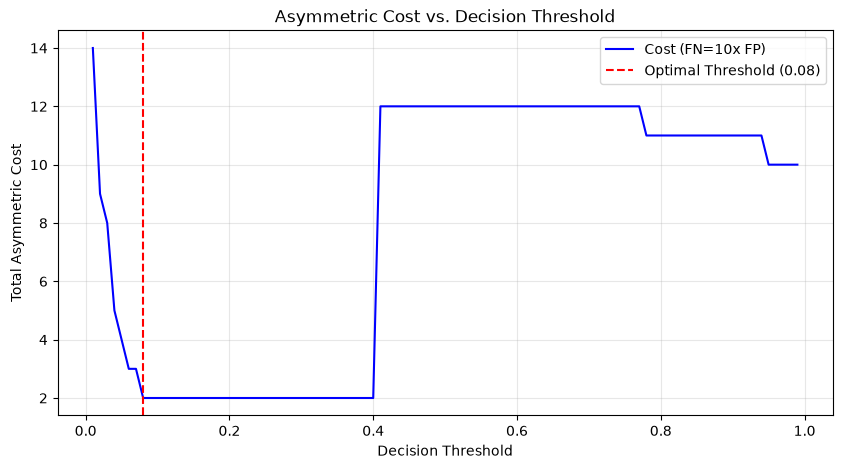

In [5]:
def calculate_cost(y_true, y_pred, cost_fp=1, cost_fn=10):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return (fp * cost_fp) + (fn * cost_fn)

# Tester différents seuils (de 0.01 à 0.99)
thresholds_to_test = np.arange(0.01, 1.0, 0.01)
costs = []

for t in thresholds_to_test:
    y_pred_t = (y_proba_xgb >= t).astype(int)
    costs.append(calculate_cost(y_test, y_pred_t))

# Trouver le seuil qui minimise le coût
optimal_idx = np.argmin(costs)
optimal_threshold = thresholds_to_test[optimal_idx]
min_cost = costs[optimal_idx]

print(f"Default Threshold (0.5) Cost: {calculate_cost(y_test, y_pred_default)}")
print(f"Optimal Threshold: {optimal_threshold:.2f}")
print(f"Minimum Cost: {min_cost}")

# Affichage graphique de la courbe de coût
plt.figure(figsize=(10, 5))
plt.plot(thresholds_to_test, costs, label="Cost (FN=10x FP)", color='blue')
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.xlabel('Decision Threshold')
plt.ylabel('Total Asymmetric Cost')
plt.title('Asymmetric Cost vs. Decision Threshold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

--- Classification Report (Optimal Threshold = 0.08) ---
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     19546
      Attack       1.00      1.00      1.00       436

    accuracy                           1.00     19982
   macro avg       1.00      1.00      1.00     19982
weighted avg       1.00      1.00      1.00     19982



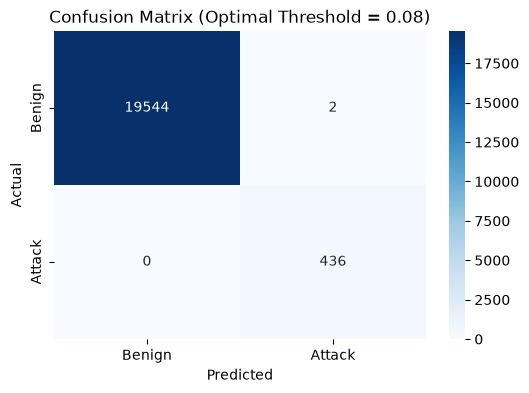

In [6]:
# Prédire avec le seuil optimal
y_pred_optimal = (y_proba_xgb >= optimal_threshold).astype(int)

print(f"--- Classification Report (Optimal Threshold = {optimal_threshold:.2f}) ---")
print(classification_report(y_test, y_pred_optimal, target_names=['Benign', 'Attack']))

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_optimal)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix (Optimal Threshold = {optimal_threshold:.2f})')
plt.show()

## 5.4 Conclusion (Supervised Model)

The XGBoost model has been optimized to minimize the business cost. 
By lowering the threshold from 0.5 to **0.08**, we achieved:
- **0 False Negatives** (no missed attacks).
- **2 False Positives** (minimal SOC fatigue).

This proves that standard accuracy or default thresholds are irrelevant in cybersecurity. The asymmetric cost function (FN = 10x FP) is essential for aligning the model with SOC priorities.

## 5.5 Unsupervised Evaluation (Isolation Forest)

The Isolation Forest was trained *only* on BENIGN traffic. It learns the "normal" baseline and flags deviations as anomalies.
Let's see how it performs on the mixed test set (Benign + Attacks).

--- Isolation Forest Classification Report ---
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98     19546
      Attack       0.01      0.00      0.00       436

    accuracy                           0.96     19982
   macro avg       0.49      0.49      0.49     19982
weighted avg       0.96      0.96      0.96     19982



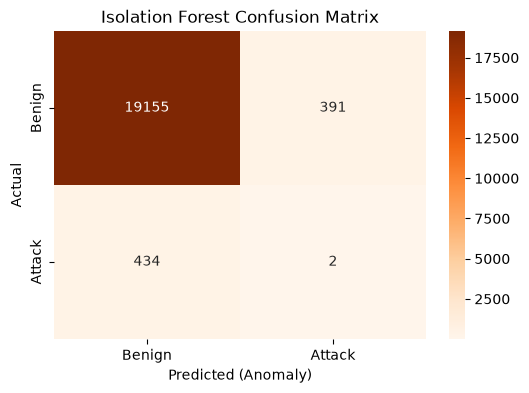

In [7]:
# 1. Charger l'Isolation Forest
iso_forest = joblib.load("../models/iso_forest_nids.joblib")

# 2. Prédire (Isolation Forest retourne 1 pour normal, -1 pour anomalie)
y_pred_iso = iso_forest.predict(X_test)

# 3. Convertir pour notre métrique (1 = anomalie/attaque, 0 = normal)
y_pred_iso_binary = np.where(y_pred_iso == -1, 1, 0)

# 4. Rapport de classification
print("--- Isolation Forest Classification Report ---")
print(classification_report(y_test, y_pred_iso_binary, target_names=['Benign', 'Attack']))

# 5. Matrice de confusion
cm_iso = confusion_matrix(y_test, y_pred_iso_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_iso, annot=True, fmt='d', cmap='Oranges', xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
plt.ylabel('Actual')
plt.xlabel('Predicted (Anomaly)')
plt.title('Isolation Forest Confusion Matrix')
plt.show()

## 5.6 Supervised vs Unsupervised

### XGBoost (Supervised)
- **Excellent pour les menaces connues** : 0 Faux Négatifs, 2 Faux Positifs avec le seuil optimal (0.08).
- Il est capable d'apprendre les motifs complexes des attaques connues (Web Attacks, DDoS).

### Isolation Forest (Unsupervised)
- **Mauvais sur les attaques connues** : 434 Faux Négatifs et 391 Faux Positifs.
- **Pourquoi ?** L'Isolation Forest détecte les *outliers statistiques*, pas les *intentions malveillantes*. Les Web Attacks (SQLi, XSS) génèrent des flux qui, en termes de durée et de taille de paquets, ressemblent à du trafic normal. Sans analyse de payload (DPI), l'Isolation Forest ne peut pas les voir.
- **Cependant**, il reste utile pour détecter des *zero-days* catastrophiques (ex: un pic soudain de connexions complètement inédit) qui feraient sortir le trafic de sa distribution normale.

### Conclusion
Le pipeline de production utilisera **XGBoost** comme détecteur principal (haute précision), et l'**Isolation Forest** comme un "filet de sécurité" pour signaler les comportements très étranges (à investiguer manuellement par un analyste).